# Transformée de Fourier 2D et filtres

1. FFT 2D d'images entières : module du spectre et spectre radial ;
2. filtres **passe-bas** et **passe-bande** appliqués dans l'espace de Fourier sur la bande utile (y 500-1200), puis FFT inverse pour revenir à une image.

Les fréquences sont en **cycles par pixel** : 0,5 = détail de 2 px (fréquence de Nyquist), 0,1 = 10 px, 0,01 = 100 px.

In [1]:
import sys
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor
from datetime import datetime

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from bucket import Bucket, DATA_DIR

plt.rcParams["figure.dpi"] = 70
b = Bucket()

CROP_Y0, CROP_Y1 = 500, 1200   # bande utile : sous le haut de l'enrochement, au-dessus de la plage du premier plan
W0 = 1919                      # largeur des images


def fetch(key):
    """Chemin local de l'image, téléchargée dans data/raw/ si elle n'y est pas déjà."""
    p = DATA_DIR / key
    if not p.exists():
        p.parent.mkdir(parents=True, exist_ok=True)
        b.s3.download_file(b.name, key, str(p))
    return p


def load_band(key, scale=1, gray=False):
    """Bande CROP_Y0-CROP_Y1 en float (0-1), décodée directement à 1/scale (rapide)."""
    im = Image.open(fetch(key))
    if scale > 1:
        im.draft("L" if gray else "RGB", (im.size[0] // scale, im.size[1] // scale))
    s = W0 / im.size[0]
    im = im.convert("L" if gray else "RGB").crop((0, round(CROP_Y0 / s), im.size[0], round(CROP_Y1 / s)))
    return np.asarray(im, dtype=np.float32) / 255


In [2]:
# Quelques images typiques (clé dans le bucket)
EXEMPLES = {
    "nette 3 nov":      "romanche-01/2026/11/03/104512_02821fd2_s.jpg",
    "crue 30 mai":      "romanche-01/2026/05/30/113001_6f159d1d_s.jpg",
    "5 juillet":        "romanche-01/2026/07/05/110011_82f0a816_s.jpg",
    "brumeuse 16 sept": "romanche-01/2026/09/16/110012_8e17c446_s.jpg",
    "brouillard 12 oct": "romanche-01/2026/10/12/120006_16950012_s.jpg",
}
EXT = [0, W0, CROP_Y1, CROP_Y0]   # pour imshow : axes en pixels de l'image d'origine
AR = W0 / (CROP_Y1 - CROP_Y0)     # proportions de la bande (~2.7)

## 1. FFT 2D des images entières
On multiplie l'image par une fenêtre de Hann 2D avant la FFT : sans elle, les bords de l'image (que la FFT suppose périodique) créent une croix parasite dans le spectre.

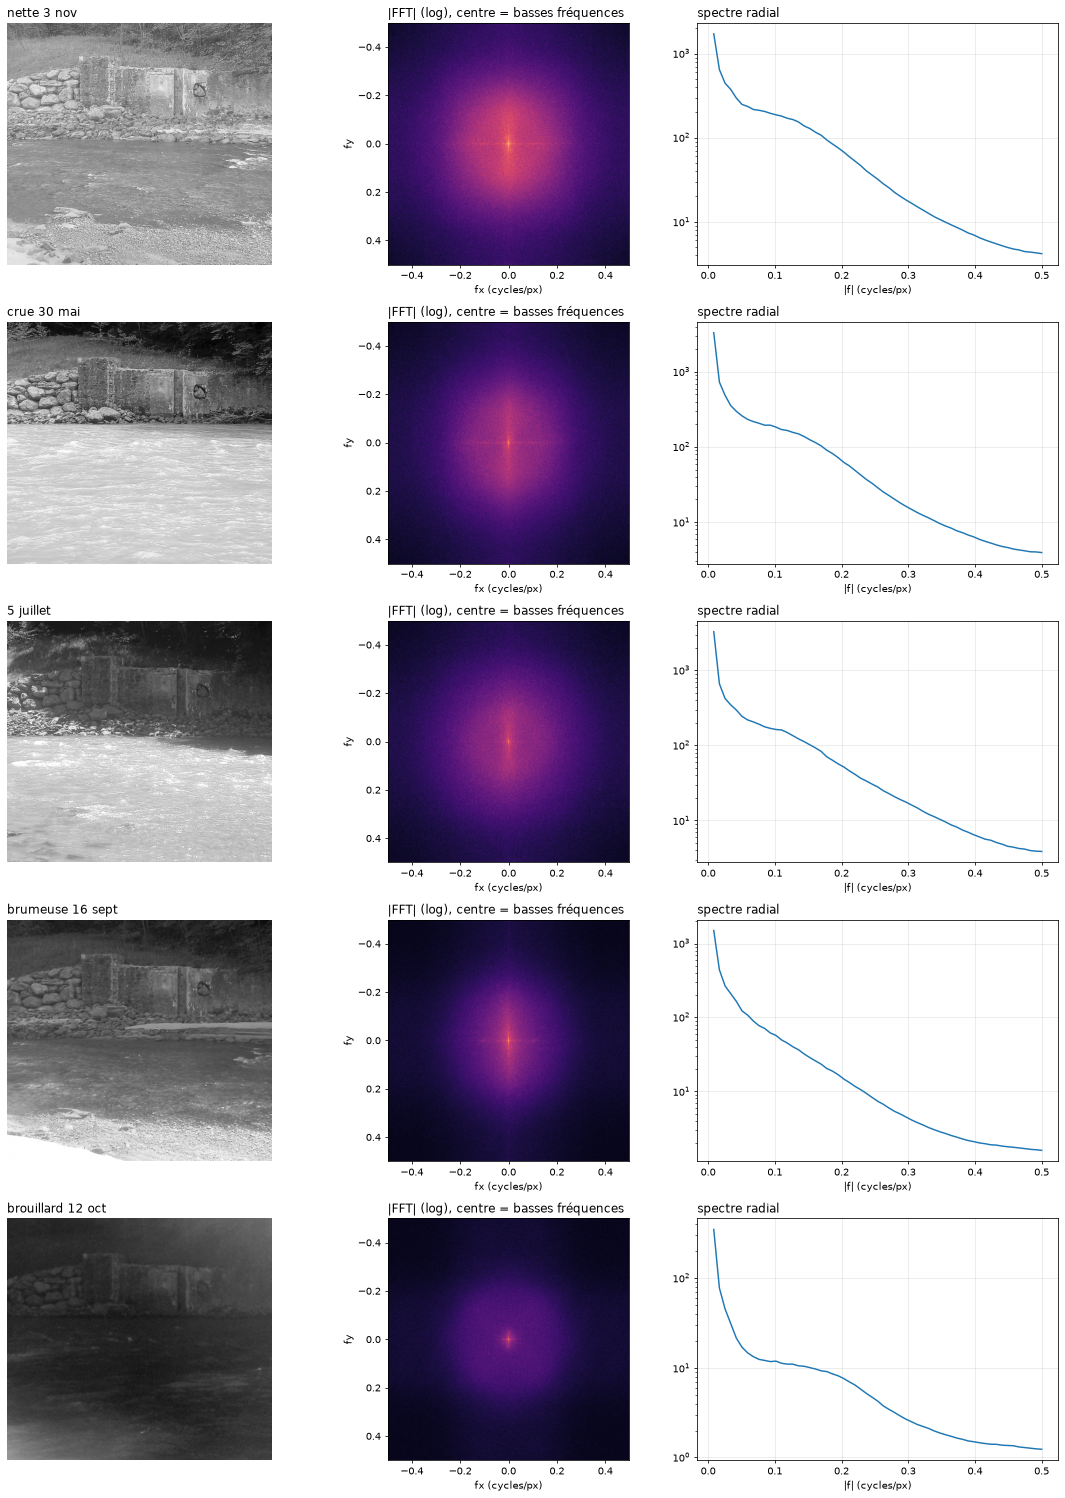

In [3]:
fig, ax = plt.subplots(len(EXEMPLES), 3, figsize=(16, 4.3 * len(EXEMPLES)))
for i, (t, k) in enumerate(EXEMPLES.items()):
    g = np.asarray(Image.open(fetch(k)).convert("L"), dtype=float) / 255
    win = np.outer(np.hanning(g.shape[0]), np.hanning(g.shape[1]))
    F = np.fft.fftshift(np.fft.fft2((g - g.mean()) * win))
    # spectre radial : amplitude moyenne en fonction de |f|
    fy = np.fft.fftshift(np.fft.fftfreq(g.shape[0]))[:, None]
    fx = np.fft.fftshift(np.fft.fftfreq(g.shape[1]))[None, :]
    r = np.hypot(fx, fy)
    bins = np.linspace(0, 0.5, 60)
    idx = np.digitize(r.ravel(), bins)
    rad = [np.abs(F).ravel()[idx == j].mean() for j in range(1, len(bins))]
    ax[i, 0].imshow(g, cmap="gray"); ax[i, 0].set_title(t, loc="left"); ax[i, 0].axis("off")
    ax[i, 1].imshow(np.log1p(np.abs(F)), cmap="magma", extent=[-.5, .5, .5, -.5])
    ax[i, 1].set_title("|FFT| (log), centre = basses fréquences", loc="left")
    ax[i, 1].set_xlabel("fx (cycles/px)"); ax[i, 1].set_ylabel("fy")
    ax[i, 2].semilogy(bins[1:], rad); ax[i, 2].grid(alpha=.3)
    ax[i, 2].set_title("spectre radial", loc="left"); ax[i, 2].set_xlabel("|f| (cycles/px)")
plt.tight_layout(); plt.show()

## 2. Filtres dans l'espace de Fourier
- **passe-bas gaussien** : $H(f) = e^{-(f/f_c)^2/2}$ — garde les structures plus grandes que ~$1/f_c$ pixels (gaussien plutôt qu'un disque à bord net, qui crée des oscillations : effet de Gibbs) ;
- **passe-bande** : différence de deux gaussiennes, garde à peu près $[f_1, f_2]$ ;
- **passe-haut** : $1 - H_{\text{passe-bas}}$, garde les détails plus petits que ~$1/f_c$ pixels (contours, texture).

Avant la FFT, l'image est prolongée **par symétrie miroir** puis recoupée après : cela supprime l'effet de bord (sinon le haut de l'image se mélange avec le bas).

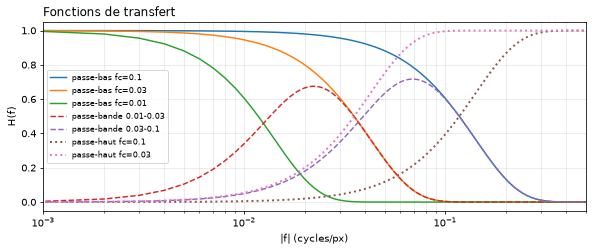

In [4]:
def fourier_filter(im, H):
    """Applique un filtre H(|f|) (|f| en cycles/px) à une image (h, w) ou (h, w, 3)."""
    h, w = im.shape[:2]
    p = np.pad(im, ((h, h), (w, w)) + ((0, 0),) * (im.ndim - 2), mode="symmetric")
    r = np.hypot(np.fft.fftfreq(p.shape[0])[:, None], np.fft.fftfreq(p.shape[1])[None, :])
    Hr = H(r)[(...,) + (None,) * (im.ndim - 2)]
    out = np.real(np.fft.ifft2(np.fft.fft2(p, axes=(0, 1)) * Hr, axes=(0, 1)))
    return out[h:2 * h, w:2 * w]


def lowpass(fc):
    return lambda f: np.exp(-(f / fc) ** 2 / 2)


def bandpass(f1, f2):
    return lambda f: np.exp(-(f / f2) ** 2 / 2) - np.exp(-(f / f1) ** 2 / 2)


def highpass(fc):
    return lambda f: 1 - np.exp(-(f / fc) ** 2 / 2)


# forme des filtres
f = np.linspace(0, 0.5, 500)
plt.figure(figsize=(10, 3.5))
for fc in (0.1, 0.03, 0.01):
    plt.plot(f, lowpass(fc)(f), label=f"passe-bas fc={fc}")
for f1, f2 in ((0.01, 0.03), (0.03, 0.1)):
    plt.plot(f, bandpass(f1, f2)(f), "--", label=f"passe-bande {f1}-{f2}")
for fc in (0.1, 0.03):
    plt.plot(f, highpass(fc)(f), ":", lw=2, label=f"passe-haut fc={fc}")
plt.xscale("log"); plt.xlim(1e-3, 0.5); plt.xlabel("|f| (cycles/px)"); plt.ylabel("H(f)")
plt.grid(alpha=.3, which="both"); plt.legend(fontsize=8); plt.title("Fonctions de transfert", loc="left"); plt.show()

### Application sur la bande utile
Les images sont traitées à 1/2 de la résolution (plus rapide) : les fréquences de coupure sont multipliées par 2 pour rester exprimées en pixels de l'image d'origine. Les passe-bande et passe-haut (de moyenne nulle) sont affichés en niveaux de gris centrés (gris = 0).

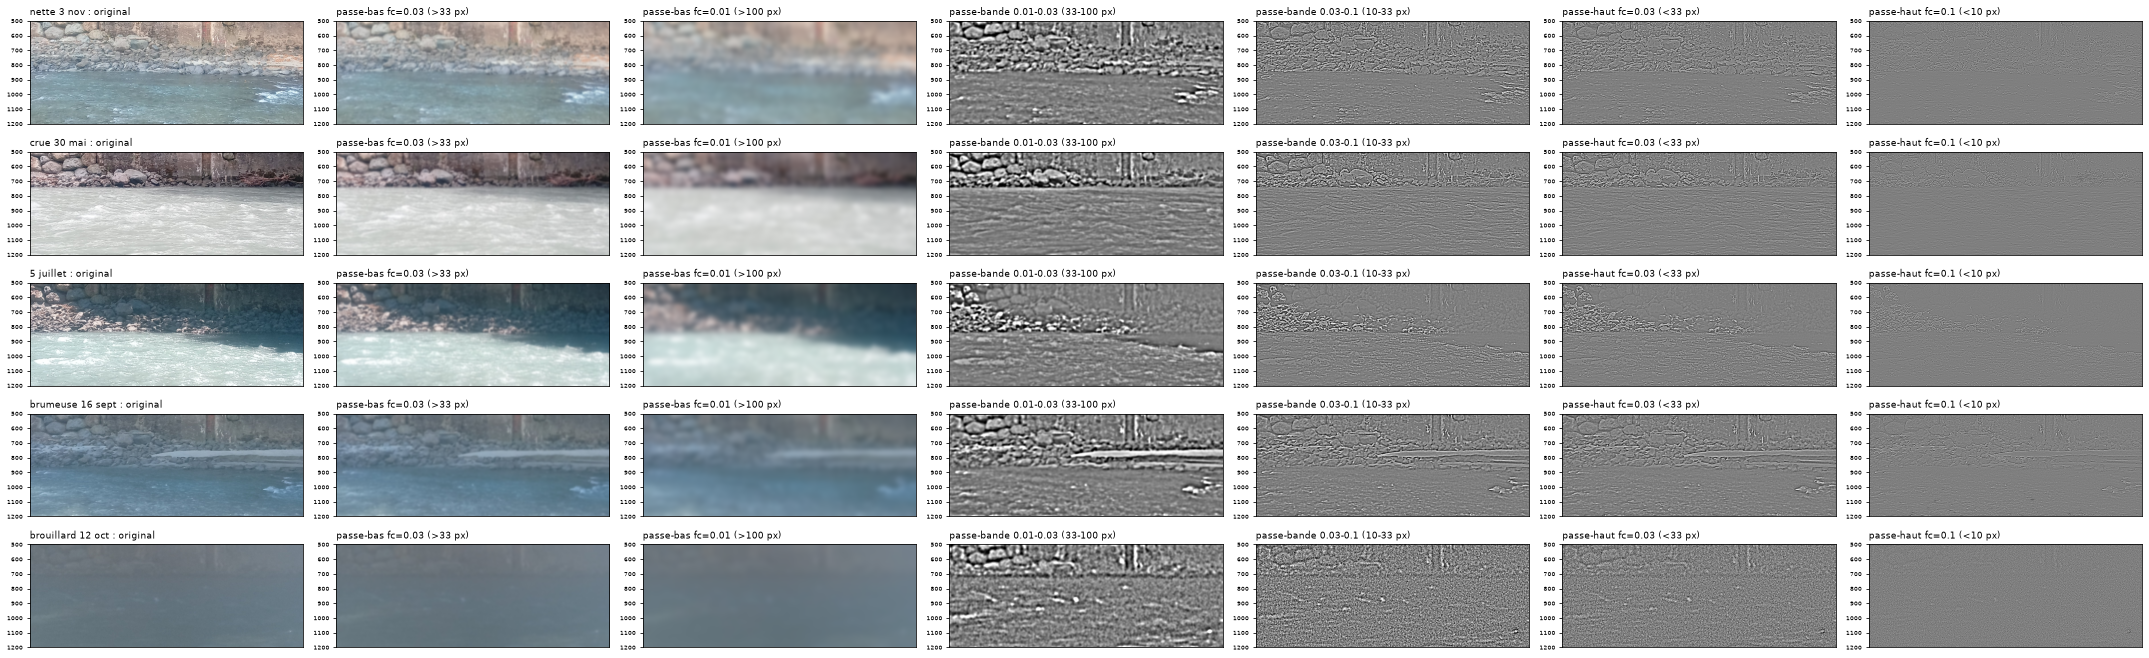

In [5]:
S = 2
COLS = [("passe-bas fc=0.03 (>33 px)", "lp", 0.03), ("passe-bas fc=0.01 (>100 px)", "lp", 0.01),
        ("passe-bande 0.01-0.03 (33-100 px)", "bp", (0.01, 0.03)), ("passe-bande 0.03-0.1 (10-33 px)", "bp", (0.03, 0.1)),
        ("passe-haut fc=0.03 (<33 px)", "hp", 0.03), ("passe-haut fc=0.1 (<10 px)", "hp", 0.1)]
fig, ax = plt.subplots(len(EXEMPLES), len(COLS) + 1, figsize=(4.4 * (len(COLS) + 1), 1.9 * len(EXEMPLES)))
for i, (t, k) in enumerate(EXEMPLES.items()):
    im = load_band(k, S)
    ax[i, 0].imshow(im, extent=EXT, aspect="auto"); ax[i, 0].set_title(f"{t} : original", fontsize=9, loc="left")
    for j, (ct, kind, p) in enumerate(COLS, 1):
        if kind == "lp":
            ax[i, j].imshow(np.clip(fourier_filter(im, lowpass(p * S)), 0, 1), extent=EXT, aspect="auto")
        else:
            H = bandpass(p[0] * S, p[1] * S) if kind == "bp" else highpass(p * S)
            out = fourier_filter(im, H).mean(axis=2)
            v = np.percentile(np.abs(out), 99) + 1e-6
            ax[i, j].imshow(out, cmap="gray", vmin=-v, vmax=v, extent=EXT, aspect="auto")
        ax[i, j].set_title(ct, fontsize=9, loc="left")
for a in ax.ravel():
    a.set_xticks([]); a.tick_params(labelsize=6)
plt.tight_layout(); plt.show()